## NoteBook for metadata ISIC2018

After analysis we can confirm that is no metadata file for HAM10000. 
The file we tought might be one (ISIC2018_Task3_Training_GroundTruth.csv) relates to the HAM10000.
Consequently, this notebook maybe redundant. It only provices a classification distribution between malignant and benin lesions. Other metadata analysis is provided somewhere else.
ISIC 2018 segmentation images do not include diagnostic labels; therefore, diagnostic stratification is performed exclusively on HAM10000.

### Insuring the folders are clean and contains only the required file type
```
data/isic2018/
|--  images/        # .jpg only
|--  masks/         # .png only
|--  txt/
  |--  images/      # .txt originally from images/
  |--  masks/       # .txt originally from masks/


data/ham10000/
|--  images/        # .jpg only
|--  masks/         # .png only
|--  txt/
  |--  images/      # .txt originally from images/
  |--  masks/       # .txt originally from masks/
|--HAM10000_metadata.csv
|--ISIC2018_Task3_Training_GroundTruth.csv
```


### SKIN Lesion Diagnostic categories
The diagnostic categories and abbreviations follow the definitions provided in the HAM10000 dataset and the ISIC 2018 challenge, which are widely used benchmarks in dermatological image analysis.

| Abbreviation | Full name                                     | Description                                                         | Malignant / Benign |
| ------------ | --------------------------------------------- | ------------------------------------------------------------------- | ------------------ |
| **MEL**      | Melanoma                                      | Malignant tumor of melanocytes; most dangerous form of skin cancer. | **Malignant**      |
| **BCC**      | Basal Cell Carcinoma                          | Slow-growing skin cancer originating from basal epidermal cells.    | **Malignant**      |
| **AKIEC**    | Actinic Keratoses / Intraepithelial Carcinoma | Precancerous lesions that may progress to squamous cell carcinoma.  | Benign*            |
| **NV**       | Melanocytic Nevi                              | Common benign moles formed by clusters of melanocytes.              | Benign             |
| **BKL**      | Benign Keratosis-like Lesions                 | Includes seborrheic keratoses and similar benign proliferations.    | Benign             |
| **DF**       | Dermatofibroma                                | Benign fibrous skin nodules, often following minor skin trauma.     | Benign             |
| **VASC**     | Vascular Lesions                              | Benign vascular tumors such as angiomas or hemorrhages.             | Benign             |

* Note on AKIEC:
AKIEC lesions are clinically precancerous. In most machine learning and ISIC/HAM10000 studies, they are grouped under benign for binary classification, although they represent a higher-risk category than other benign lesions.

Classes: ['bkl' 'nv' 'df' 'mel' 'vasc' 'bcc' 'akiec']
     lesion_id      image_id   dx dx_type   age   sex localization  \
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp   
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp   
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp   
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp   
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear   

        dataset binary_label  
0  vidir_modern       benign  
1  vidir_modern       benign  
2  vidir_modern       benign  
3  vidir_modern       benign  
4  vidir_modern       benign  
               age
count  9958.000000
mean     51.863828
std      16.968614
min       0.000000
25%      40.000000
50%      50.000000
75%      65.000000
max      85.000000


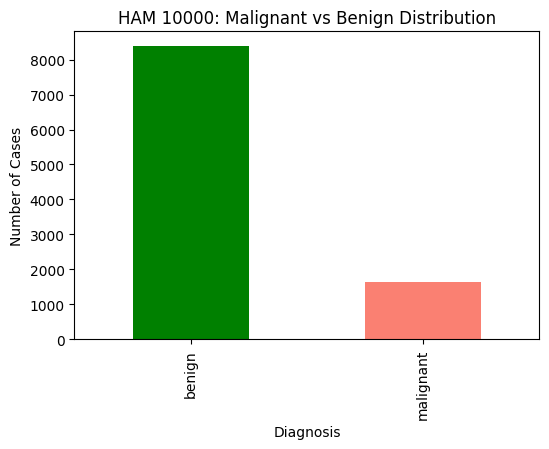

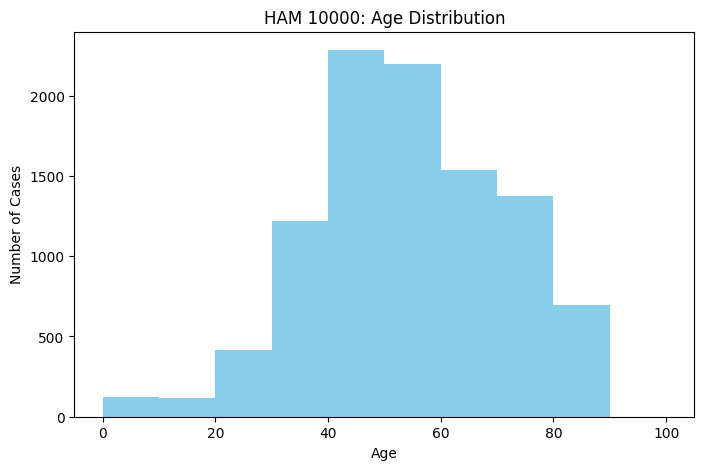

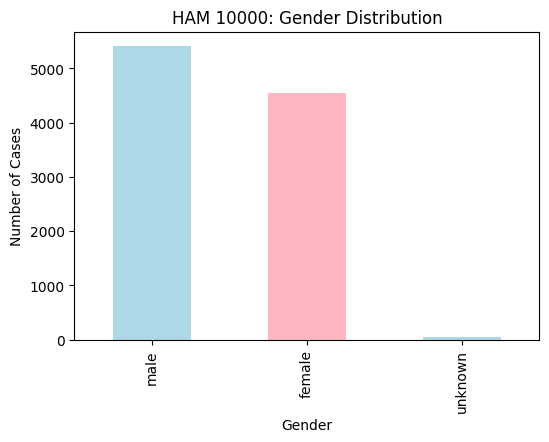

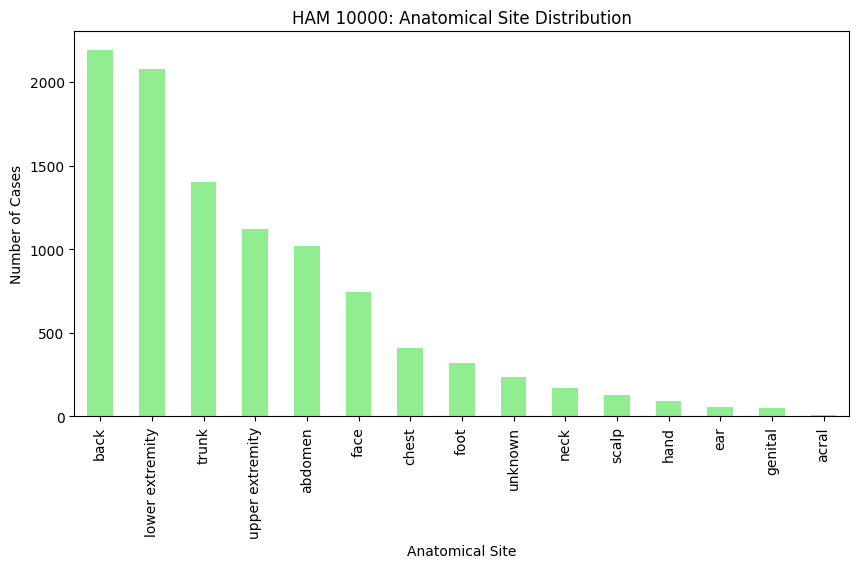

In [19]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

ROOT = Path("..") # Adjust if this notebook is not in <src>/
ISIC_DIR = ROOT / "data" / "isic2018"
ISIC_IMG_DIR  = ISIC_DIR / "images"
ISIC_MASK_DIR = ISIC_DIR / "masks"

HAM_DIR = ROOT / "data" / "ham10000"
HAM_IMG_DIR = HAM_DIR / "images"
HAM_MASK_DIR = HAM_DIR / "masks"  # Tschandl masks unzipped
HAM_META = HAM_DIR / "HAM10000_metadata.csv"
HAM_GT = HAM_DIR / "ISIC2018_Task3_Training_GroundTruth.csv" # ground truth for ISIC 2018 Task 3 - related to HAM10000

assert ISIC_IMG_DIR.exists(), f"Missing {ISIC_IMG_DIR}"
assert ISIC_MASK_DIR.exists(), f"Missing {ISIC_MASK_DIR}"


# Load metadata
ham_gt = pd.read_csv(HAM_GT)
ham_meta = pd.read_csv(HAM_META)   

print(f'Classes: {ham_meta["dx"].unique()}')

# label mapping for HAM10000
malignant = ["mel", "bcc"]
ham_meta["binary_label"] = (
    ham_meta["dx"].isin(malignant).map({True: "malignant", False: "benign"})
)
print(ham_meta.head())
print(ham_meta.describe())

# plot malignant vs benign distribution
plt.figure(figsize=(6,4))
ham_meta["binary_label"].value_counts().plot(kind="bar", color=["green", "salmon"])
plt.title("HAM 10000: Malignant vs Benign Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases")
plt.show() 


# Plot age distribution
bins_labels = ["0-10", "11-20", "21-30", "31-40", "41-50", "51-60", "61-70", "71-80", "81-90", "91-100"]
bins = [0,10,20,30,40,50,60,70,80,90,100]
ham_meta["age_group"] = pd.cut(ham_meta["age"], bins=bins, labels=bins_labels, right=True)
plt.figure(figsize=(8,5))   
ham_meta["age"].dropna().astype(int).plot(kind="hist", bins=bins, color="skyblue")
plt.title("HAM 10000: Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Cases")
plt.show()

# Plot gender distribution


plt.figure(figsize=(6,4))
ham_meta["sex"].value_counts().plot(kind="bar", color=["lightblue", "lightpink"])
plt.title("HAM 10000: Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Cases")
plt.show()  

# Plot anatomical site distribution
plt.figure(figsize=(10,5))
ham_meta["localization"].value_counts().plot(kind="bar", color="lightgreen")
plt.title("HAM 10000: Anatomical Site Distribution")   
plt.xlabel("Anatomical Site")
plt.ylabel("Number of Cases")
plt.show()


The ISIC 2018 segmentation dataset does not provide diagnostic labels for the images used in Task 1. Consequently, diagnostic stratification was not performed for ISIC 2018, and benign/malignant analysis was conducted exclusively using the HAM10000 dataset, which provides curated diagnostic metadata.
